In [1]:
%pip install nilearn scipy pandas

In [3]:
from pathlib import Path
import json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import plotting, masking, image
from scipy.signal import butter, sosfiltfilt

In [5]:
BASE_DIR = Path(r"C:\Users\praja\functional-connectivity")

PARTICIPANT = "sub-NDARINVYT858CBN"

FMRI_FILE = (
    BASE_DIR / "data" / "raw" /
    PARTICIPANT / "func" /
    f"{PARTICIPANT}_task-restAP_run-01_bold.nii.gz"
)

OUTPUT_DIR = BASE_DIR / "milestone_3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fmri_img = nib.load(str(FMRI_FILE))

print("Dimensions:", fmri_img.shape)
print("TR:", fmri_img.header.get_zooms()[3])

Dimensions: (104, 104, 72, 488)
TR: 0.8


In [7]:
brain_mask_img = masking.compute_epi_mask(
    fmri_img,
    lower_cutoff=0.2,
    upper_cutoff=0.85
)

mask_data = brain_mask_img.get_fdata() > 0

print("Brain mask created.")
print("Brain voxels:", int(mask_data.sum()))
print("Mask dimensions:", mask_data.shape)

nib.save(
    brain_mask_img,
    OUTPUT_DIR / "brain_mask.nii.gz"
)

Brain mask created.
Brain voxels: 153569
Mask dimensions: (104, 104, 72)


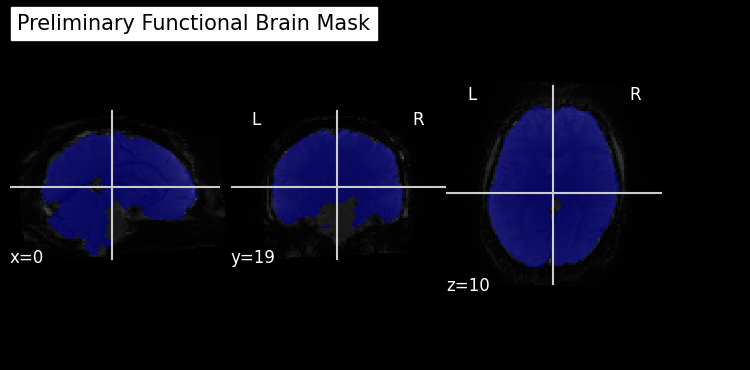

In [9]:
plotting.plot_roi(
    brain_mask_img,
    bg_img=image.mean_img(fmri_img),
    title="Preliminary Functional Brain Mask",
    display_mode="ortho",
    cut_coords=None
)

plt.savefig(
    OUTPUT_DIR / "brain_mask_visualisation.png",
    dpi=300
)

plt.show()

In [11]:
fmri_data = fmri_img.get_fdata(dtype=np.float32)

voxel_timeseries = fmri_data[mask_data, :]

print("Voxel time series:", voxel_timeseries.shape)
print("Number of brain voxels:", voxel_timeseries.shape[0])
print("Time points:", voxel_timeseries.shape[1])

Voxel time series: (153569, 488)
Number of brain voxels: 153569
Time points: 488


In [13]:
from scipy.signal import detrend

clean_data = detrend(
    voxel_timeseries,
    axis=1,
    type="linear"
)

voxel_mean = clean_data.mean(axis=1, keepdims=True)
voxel_std = clean_data.std(axis=1, keepdims=True)

voxel_std[voxel_std == 0] = 1

standardised_data = (
    clean_data - voxel_mean
) / voxel_std

print("Detrending completed.")
print("Standardised shape:", standardised_data.shape)
print("Mean:", float(np.mean(standardised_data)))

Detrending completed.
Standardised shape: (153569, 488)
Mean: 6.254864404198202e-10


In [15]:
TR = float(fmri_img.header.get_zooms()[3])
sampling_frequency = 1 / TR

sos = butter(
    4,
    [0.01, 0.1],
    btype="bandpass",
    fs=sampling_frequency,
    output="sos"
)

filtered_data = sosfiltfilt(
    sos,
    standardised_data,
    axis=1
)

print("Filtering completed.")
print("Filtered shape:", filtered_data.shape)

Filtering completed.
Filtered shape: (153569, 488)


In [17]:
np.save(
    OUTPUT_DIR / "filtered_voxel_timeseries.npy",
    filtered_data
)

np.save(
    OUTPUT_DIR / "brain_mask_voxel_timeseries.npy",
    voxel_timeseries
)

report = {
    "dataset": "ds005237",
    "participant": PARTICIPANT,
    "input": "restAP_run-01",
    "brain_mask_voxels": int(mask_data.sum()),
    "timepoints": int(filtered_data.shape[1]),
    "TR_seconds": TR,
    "detrending": "linear",
    "standardisation": "voxel-wise z-score",
    "temporal_filter_hz": [0.01, 0.1],
    "motion_correction": False,
    "nuisance_regression": False,
    "susceptibility_distortion_correction": False,
    "PA_acquisition_available": False,
    "BIDS_sidecar_available": False,
    "status": "preliminary preprocessing only"
}

with open(OUTPUT_DIR / "m3_preprocessing_report.json", "w") as f:
    json.dump(report, f, indent=4)

print("MILESTONE 3 OUTPUTS SAVED")
print(json.dumps(report, indent=4))

MILESTONE 3 OUTPUTS SAVED
{
    "dataset": "ds005237",
    "participant": "sub-NDARINVYT858CBN",
    "input": "restAP_run-01",
    "brain_mask_voxels": 153569,
    "timepoints": 488,
    "TR_seconds": 0.800000011920929,
    "detrending": "linear",
    "standardisation": "voxel-wise z-score",
    "temporal_filter_hz": [
        0.01,
        0.1
    ],
    "motion_correction": false,
    "nuisance_regression": false,
    "susceptibility_distortion_correction": false,
    "PA_acquisition_available": false,
    "BIDS_sidecar_available": false,
    "status": "preliminary preprocessing only"
}
